# Customer Churn Prediction and Business Insights for a Telecom Company

##  Project Overview

###  Problem Statement
A telecom company earns money from monthly subscriptions. When a customer **churns** (cancels the service), the company loses that recurring revenue. Winning a new customer is usually more expensive than keeping an existing one, so understanding *why* customers leave is very valuable.

###  Objectives
This project answers four simple questions:

1. How many customers are leaving, and how much monthly revenue is at risk?
2. Which groups of customers are most likely to leave (contract type, tenure, services, billing, etc.)?
3. Can a machine learning model predict which customers will churn?
4. What actions can the company take to reduce churn?

###  Dataset
- **Name:** Telco Customer Churn (IBM sample dataset, available on Kaggle)
- **Size:** 7,043 customers and 21 columns
- **Target column:** `Churn` (`Yes` = the customer left, `No` = the customer stayed)

| Group | Columns |
|---|---|
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account information | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Target | `Churn` |


##  Import Libraries and Load Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report,
                             ConfusionMatrixDisplay)

# General settings
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42                                   # makes results reproducible
PALETTE = {'No': '#4C9F70', 'Yes': '#E4572E'}       # green = stayed, red = churned

In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


##  Data Inspection

In [3]:
print('Number of rows   :', df.shape[0])
print('Number of columns:', df.shape[1])

Number of rows   : 7043
Number of columns: 21


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
print('Total missing values  :', df.isnull().sum().sum())
print('Duplicate rows        :', df.duplicated().sum())
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())

Total missing values  : 0
Duplicate rows        : 0
Duplicate customer IDs: 0


### Observations
- The dataset has **7,043 rows and 21 columns**.
- `isnull()` reports **no missing values**, and there are no duplicate customers.

##  Data Cleaning

###  Make Column Names Consistent

In [7]:
df.columns = [col[0].upper() + col[1:] for col in df.columns]
list(df.columns)

['CustomerID',
 'Gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'Tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

###  Fix the `TotalCharges` Column

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print('Missing TotalCharges after conversion:', df['TotalCharges'].isnull().sum())
df[df['TotalCharges'].isnull()][['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges']]

Missing TotalCharges after conversion: 11


,CustomerID,Tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


All of these customers have a **tenure of 0 months**, meaning they just joined and have not been billed yet. Their total charges are therefore genuinely **0**, so we fill the blanks with 0.

In [9]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print('Missing TotalCharges:', df['TotalCharges'].isnull().sum())

Missing TotalCharges: 0


### Drop the Customer ID

In [10]:
df = df.drop(columns=['CustomerID'])
print('Duplicate rows after removing ID:', df.duplicated().sum())

Duplicate rows after removing ID: 22


Some rows now look identical. This is expected: different customers can have the same plan and profile. They are real customers, so we **keep them**.

###  Make Yes/No Labels Consistent
- `SeniorCitizen` is changed from 0/1 to `No`/`Yes`, matching the other columns.
- Columns such as `OnlineSecurity` contain `No internet service` and `MultipleLines` contains `No phone service`. Both simply mean the customer does not have that feature so we group them under `No`.

In [11]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df = df.replace({'No internet service': 'No', 'No phone service': 'No'})

# Check the categories of every text column
for col in df.select_dtypes(include='object').columns:
    print(f'{col:18}', sorted(df[col].unique()))

Gender             ['Female', 'Male']
SeniorCitizen      ['No', 'Yes']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'Yes']
OnlineBackup       ['No', 'Yes']
DeviceProtection   ['No', 'Yes']
TechSupport        ['No', 'Yes']
StreamingTV        ['No', 'Yes']
StreamingMovies    ['No', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


### Create a Numeric Churn Column

In [12]:
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)
df.head()

,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   Tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

The data is now clean: correct data types, no missing values and consistent labels.

##  Exploratory Data Analysis (EDA)

### Q1: How Many Customers Churn?

In [14]:
churn_summary = pd.DataFrame({
    'Customers': df['Churn'].value_counts(),
    'Percentage (%)': (df['Churn'].value_counts(normalize=True) * 100).round(2)
})
churn_summary

,Customers,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


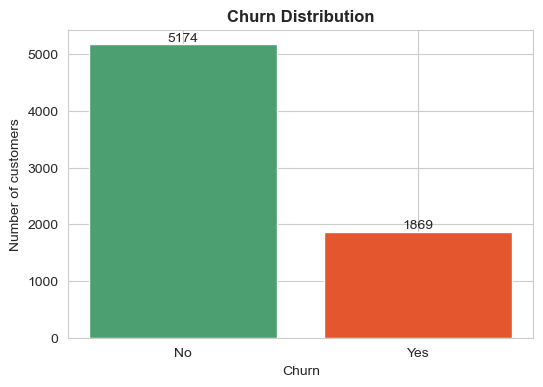

In [15]:
counts = df['Churn'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
ax.bar_label(ax.containers[0])
ax.set_title('Churn Distribution', fontweight='bold')
ax.set_xlabel('Churn')
ax.set_ylabel('Number of customers')
plt.show()

**Insight:** Out of 7,043 customers, **1,869 (26.5%) churned**. Roughly 1 in 4 customers leaves.

### Q2: How Much Revenue Is Lost to Churn?

In [16]:
total_monthly = df['MonthlyCharges'].sum()
lost_monthly = df.loc[df['Churn'] == 'Yes', 'MonthlyCharges'].sum()

print(f'Total monthly revenue (all customers) : ${total_monthly:,.2f}')
print(f'Monthly revenue lost to churn         : ${lost_monthly:,.2f}')
print(f'Share of monthly revenue lost         : {lost_monthly / total_monthly * 100:.1f}%')
print(f'Yearly revenue lost (monthly x 12)    : ${lost_monthly * 12:,.2f}')

Total monthly revenue (all customers) : $456,116.60
Monthly revenue lost to churn         : $139,130.85
Share of monthly revenue lost         : 30.5%
Yearly revenue lost (monthly x 12)    : $1,669,570.20


In [17]:
df.groupby('Churn')['MonthlyCharges'].mean().round(2).rename('Average monthly charge ($)')

Churn
No     61.27
Yes    74.44
Name: Average monthly charge ($), dtype: float64

**Insight:** Churned customers represent about **\$139,131 of monthly recurring revenue, around 30.5% of the total** (roughly \$1.67 million per year). Churned customers also paid more on average (**\$74.44 per month** vs **\$61.27** for customers who stayed). Churn therefore hurts revenue more than the customer percentage (26.5%) suggests, because the customers leaving are the ones paying more.

### Q3: Does Churn Depend on Demographics?
We check gender, senior citizen status, partner and dependents.

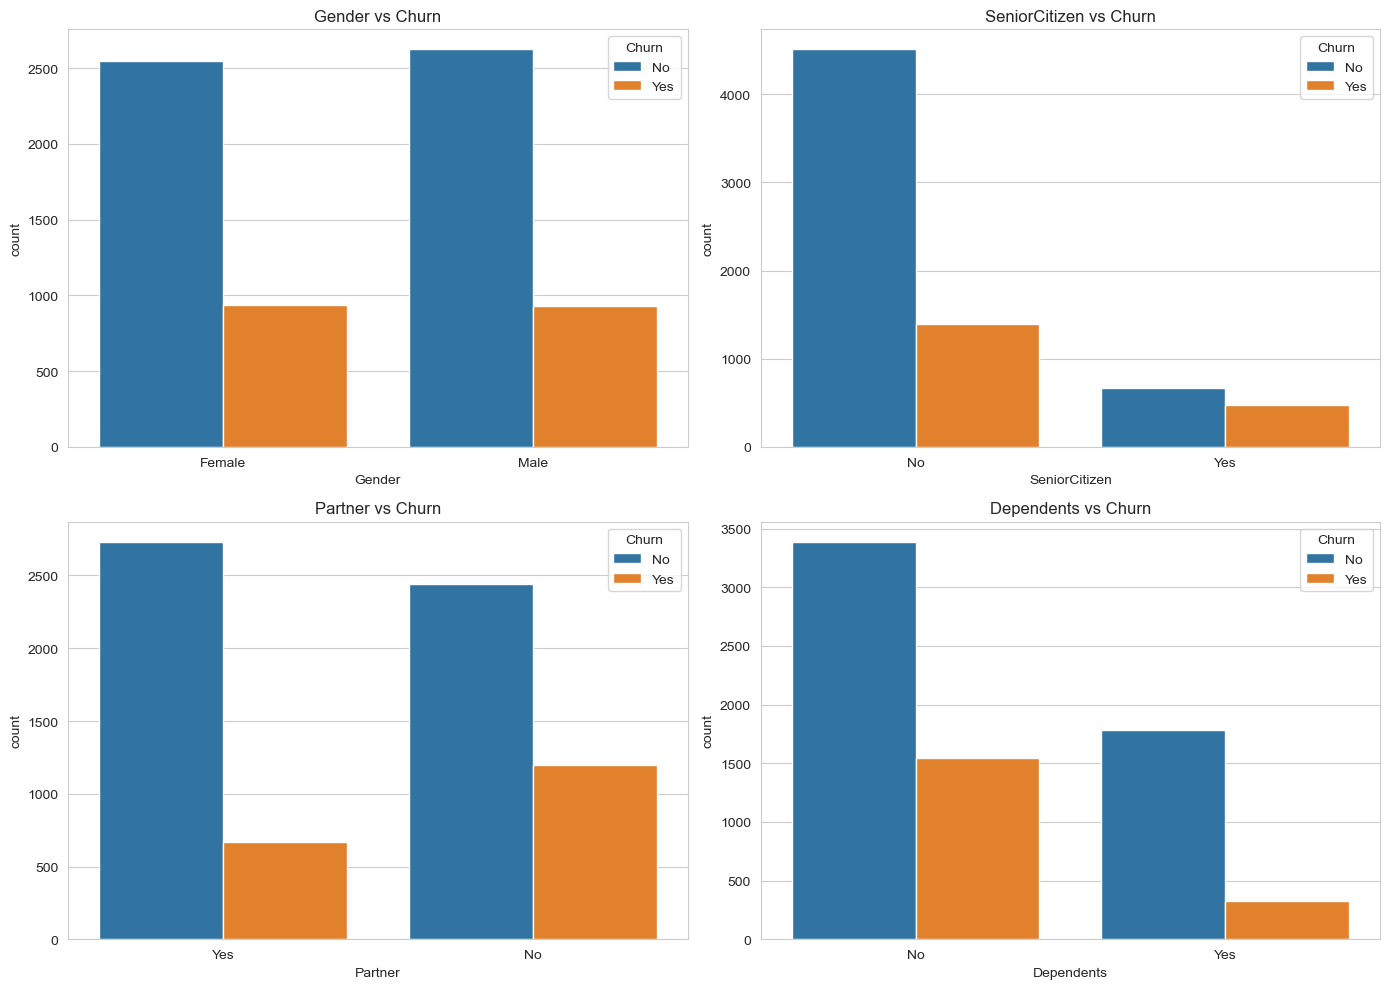

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cols = ['Gender', 'SeniorCitizen', 'Partner', 'Dependents']

for ax, col in zip(axes.flat, cols):
    sns.countplot(data=df, x=col, hue='Churn', ax=ax)
    ax.set_title(f'{col} vs Churn')

plt.tight_layout()
plt.show()

**Insights:**
Gender does not appear to have a significant impact on churn.
Senior citizens show a higher tendency to churn.
Customers without partners are more likely to leave.
Customers without dependents exhibit higher churn rates.
Customers who are single, have no dependents or are older are less settled with the company and are more likely to leave.

### Q4: Are New Customers More Likely to Leave? (Tenure)
`Tenure` is the number of months a customer has stayed with the company.

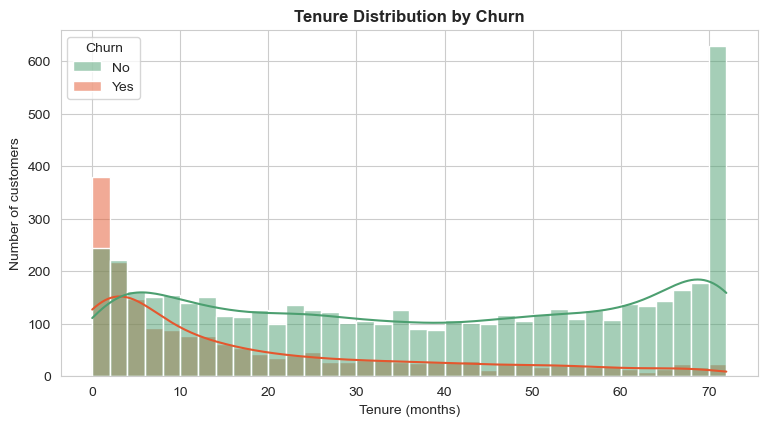

In [19]:
plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x='Tenure', hue='Churn', bins=36, kde=True, palette=PALETTE)
plt.title('Tenure Distribution by Churn', fontweight='bold')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of customers')
plt.show()

In [20]:
def plot_churn_by(column, order=None):
    plt.figure(figsize=(8,5))

    sns.countplot(
        data=df,
        x=column,
        hue='Churn',
        order=order,
        palette='Set2'
    )

    plt.title(f'{column} vs Churn')
    plt.xlabel(column)
    plt.ylabel('Number of Customers')

    plt.xticks(rotation=15)
    plt.show()

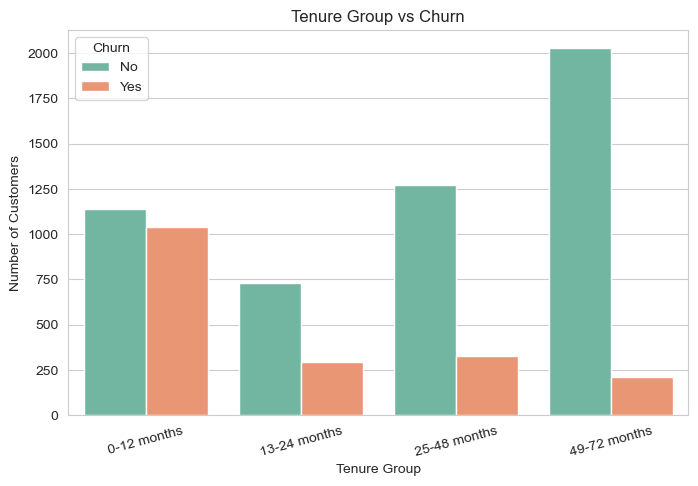

In [21]:
df['TenureGroup'] = pd.cut(
    df['Tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)

plt.figure(figsize=(8,5))

sns.countplot(
    x='TenureGroup',
    hue='Churn',
    data=df,
    palette='Set2'
)

plt.title('Tenure Group vs Churn')
plt.xlabel('Tenure Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)

plt.show()

**Insights:**
Customers in their first 12 months have the highest churn.
Churn decreases as customer tenure increases.
Long-term customers are less likely to leave.

The first year is the most critical period for keeping a customer.

###  Q5: Does the Contract Type Matter?

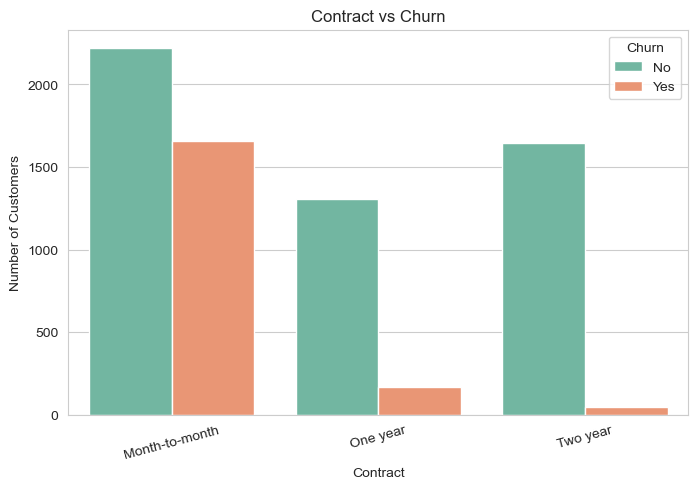

In [22]:
plot_churn_by('Contract', order=['Month-to-month', 'One year', 'Two year'])

**Insight:** Contract type is one of the strongest signals in the data.
- Month-to-month contracts: **42.7%** churn
- One-year contracts: **11.3%** churn
- Two-year contracts: **2.8%** churn

About **89% of all churners were on month-to-month contracts**. These customers can leave at any time with no commitment.

###  Q6: Which Services Are Linked to Churn?

**Internet service type first:**

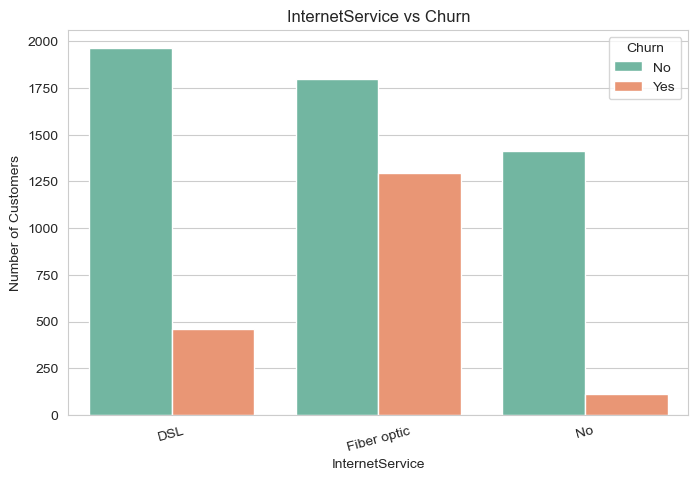

In [23]:
plot_churn_by('InternetService', order=['DSL', 'Fiber optic', 'No'])

Next, the add-on services. We only look at customers **who have internet**, because customers without internet cannot have these add-ons. For each service we compare the churn rate of customers **with** and **without** it.

In [24]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']
internet_users = df[df['InternetService'] != 'No']

addon_rates = pd.DataFrame({
    'Without service': [internet_users[internet_users[c] == 'No']['ChurnFlag'].mean() * 100 for c in addon_cols],
    'With service':    [internet_users[internet_users[c] == 'Yes']['ChurnFlag'].mean() * 100 for c in addon_cols],
}, index=addon_cols).round(1)

addon_rates

,Without service,With service
OnlineSecurity,41.8,14.6
OnlineBackup,39.9,21.5
DeviceProtection,39.1,22.5
TechSupport,41.6,15.2
StreamingTV,33.5,30.1
StreamingMovies,33.7,29.9


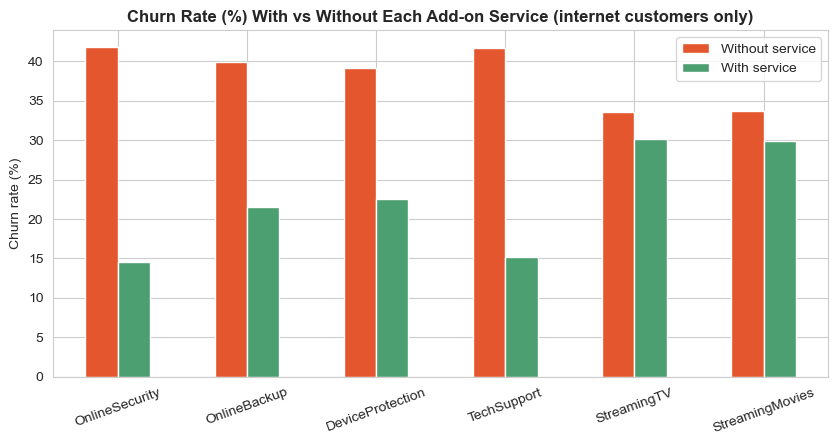

In [25]:
addon_rates.plot(kind='bar', figsize=(10, 4.5), color=['#E4572E', '#4C9F70'])
plt.title('Churn Rate (%) With vs Without Each Add-on Service (internet customers only)', fontweight='bold')
plt.ylabel('Churn rate (%)')
plt.xlabel('')
plt.xticks(rotation=20)
plt.legend(title='')
plt.show()

**Insights:**
- **Fiber optic customers churn the most (41.9%)**, compared with DSL (19.0%) and customers with no internet (7.4%). Fiber is usually the more expensive plan, so price, service quality or competition could be behind this. The data cannot tell us which.
- Customers who have **Online Security** (14.6% vs 41.8%) or **Tech Support** (15.2% vs 41.6%) churn far less than customers without them. Online Backup and Device Protection show a similar but smaller gap.
- **Streaming services** make little difference (about 30% vs 33%).

Support and security services are linked to loyalty. These customers may feel better looked after or they may simply be more engaged customers (this is a link, not proof of cause).

### Q7: Do Billing and Payment Methods Matter?

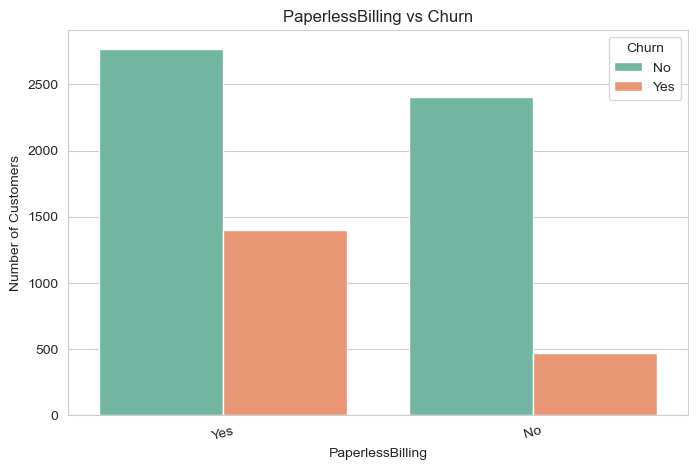

In [26]:
plot_churn_by('PaperlessBilling')

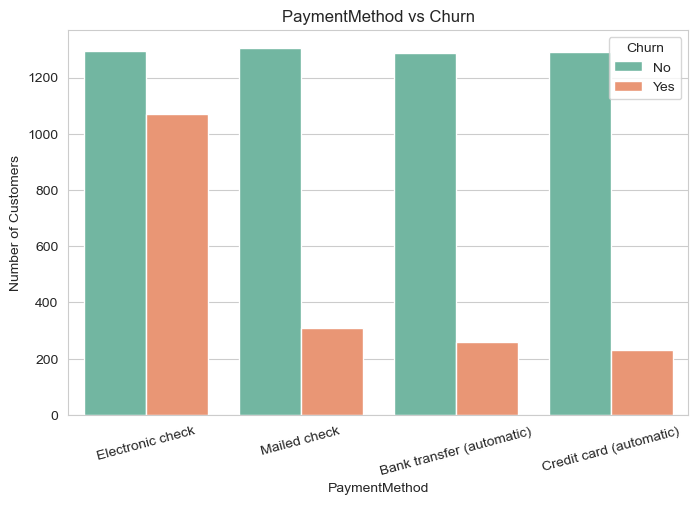

In [27]:
plot_churn_by('PaymentMethod',
              order=['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'])

**Insights:**
- Customers on **paperless billing** churn about twice as often (33.6% vs 16.3%).
- **Electronic check** users churn the most by far (**45.3%**), while customers on automatic payments (bank transfer 16.7%, credit card 15.2%) and mailed checks (19.1%) churn much less.

Automatic payments are linked to lower churn probably because the payment happens without the customer having to act each month. Paperless billing and electronic check may also be common among newer, month-to-month customers so these effects can overlap with contract type.

###  Q8: Do Higher Monthly Charges Lead to More Churn?

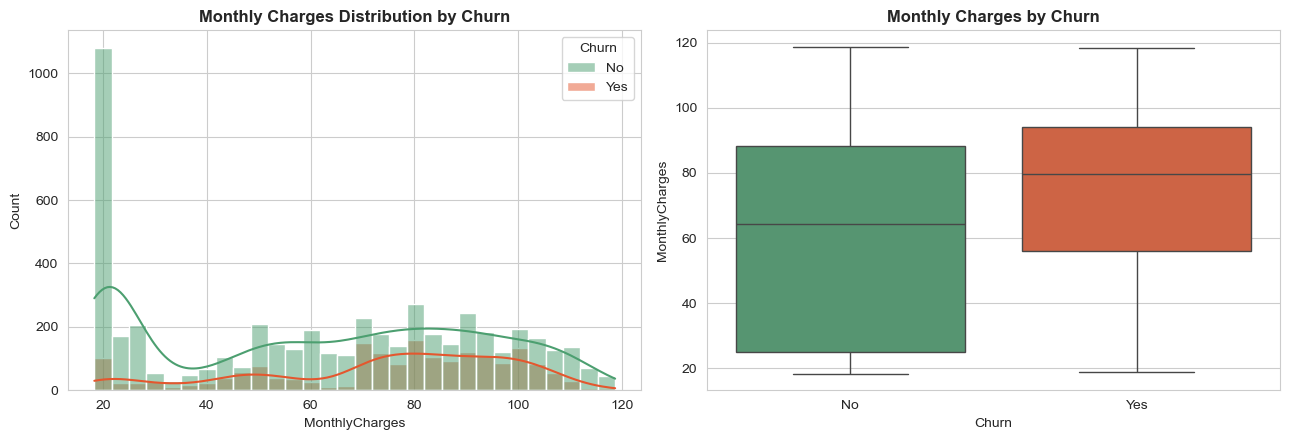

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, kde=True, palette=PALETTE, ax=axes[0])
axes[0].set_title('Monthly Charges Distribution by Churn', fontweight='bold')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, order=['No', 'Yes'], palette=PALETTE, ax=axes[1])
axes[1].set_title('Monthly Charges by Churn', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** Churned customers pay more. Their median monthly charge is about **\$79.65**, compared with **\$64.43** for customers who stayed. The large group of customers paying about \$20 per month (basic phone-only plans) rarely churns. Customers on higher-priced plans, such as fiber optic, are more likely to leave.

### Correlation Between Numeric Columns
A correlation heatmap shows how strongly numeric columns move together (values range from -1 to +1).

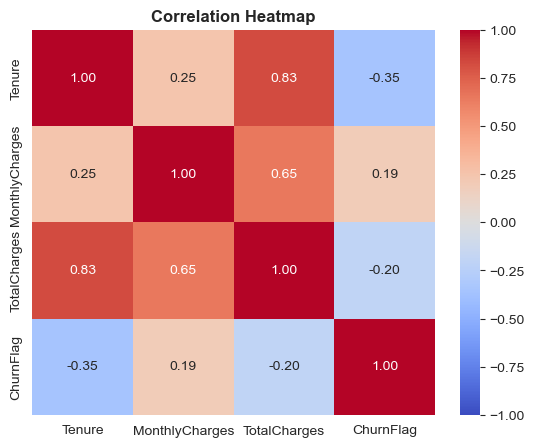

In [29]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[['Tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap', fontweight='bold')
plt.show()

**Insights:**
- `Tenure` has a **negative correlation with churn (-0.35)**: the longer a customer stays, the less likely they are to leave.
- `MonthlyCharges` has a small **positive correlation (+0.19)**: higher bills go with more churn.
- `TotalCharges` is strongly linked to `Tenure` (**0.83**), because total charges grow with every month a customer stays. Its link with churn (-0.20) mostly reflects tenure.

###  Summary of EDA Findings
Customers are **most likely to churn** when they:

| Pattern | Churn rate |
|---|---|
| Are in their **first 12 months** | 47.4% |
| Have a **month-to-month contract** | 42.7% |
| Use **fiber optic** internet | 41.9% |
| Pay by **electronic check** | 45.3% |
| Have **no online security or tech support** | about 42% |
| Are **senior citizens** | 41.7% |

Gender is **not** a factor. These patterns guide the features we give to the machine learning model.

##  Feature Engineering

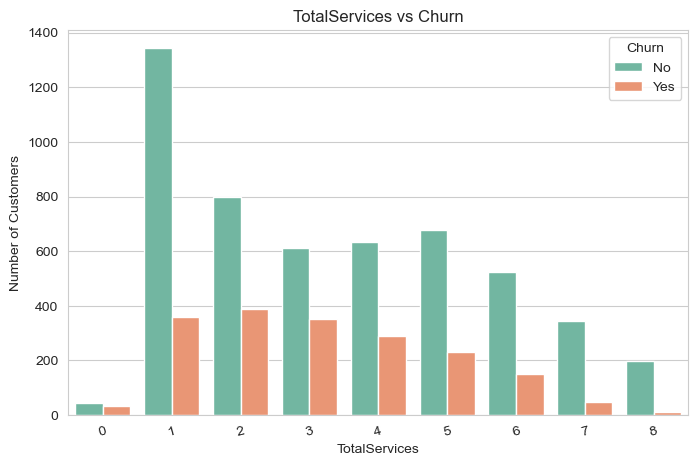

In [30]:
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

df['TotalServices'] = (df[service_cols] == 'Yes').sum(axis=1)
plot_churn_by('TotalServices', order=sorted(df['TotalServices'].unique()))

**Insight:** Customers who use **many services** churn the least (12.4% with 7 services and only 5.3% with 8). The relationship is not perfectly smooth, because the count mixes internet and phone-only customers. For example, phone-only customers (1 service) churn at 21.1%, while internet-only customers with no add-ons (0 services) churn at 43.8%. The feature still gives the model a compact summary of how involved a customer is.

##  Prepare Data for Machine Learning

In [31]:
X = df.drop(columns=['Churn', 'ChurnFlag', 'TenureGroup'])
y = df['ChurnFlag']

# One-hot encoding of the text columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print('Number of features after encoding:', X.shape[1])
X.head()

Number of features after encoding: 24


,Tenure,MonthlyCharges,TotalCharges,TotalServices,Gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,3,1,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1
2,2,53.85,108.15,3,1,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1
3,45,42.30,1840.75,3,1,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0
4,2,70.70,151.65,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Training set:', X_train.shape)
print('Test set    :', X_test.shape)
print(f'Churn rate in training set: {y_train.mean() * 100:.1f}%')
print(f'Churn rate in test set    : {y_test.mean() * 100:.1f}%')

Training set: (5634, 24)
Test set    : (1409, 24)
Churn rate in training set: 26.5%
Churn rate in test set    : 26.5%


### Scaling Numeric Columns

In [33]:
num_cols = ['Tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled[num_cols].describe().round(2)

,Tenure,MonthlyCharges,TotalCharges,TotalServices
count,5634.00,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.32,-1.54,-1.01,-1.63
25%,-0.96,-0.97,-0.83,-1.15
50%,-0.14,0.18,-0.40,-0.18
75%,0.92,0.83,0.67,0.78
max,1.61,1.79,2.80,2.23


##  Train Machine Learning Models

**What we are doing:** Training three different classification models to predict whether a customer will churn.

In [34]:
models = {
    'Logistic Regression': (
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
        X_train_scaled, X_test_scaled),
    'Decision Tree': (
        DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=RANDOM_STATE),
        X_train, X_test),
    'Random Forest': (
        RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                               class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        X_train, X_test),
}

predictions = {}      # predicted classes (0 / 1)
probabilities = {}    # predicted churn probabilities

for name, (model, X_tr, X_te) in models.items():
    model.fit(X_tr, y_train)
    predictions[name] = model.predict(X_te)
    probabilities[name] = model.predict_proba(X_te)[:, 1]
    print(f'{name} trained')

Logistic Regression trained
Decision Tree trained
Random Forest trained


##  Evaluate the Models

**What we are doing:** Measuring how well each model performs on the unseen test set.

In [35]:
results = []
for name in models:
    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, predictions[name]),
        'Precision': precision_score(y_test, predictions[name]),
        'Recall':    recall_score(y_test, predictions[name]),
        'F1-score':  f1_score(y_test, predictions[name]),
        'ROC-AUC':   roc_auc_score(y_test, probabilities[name]),
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.761,0.534,0.775,0.632,0.846
Logistic Regression,0.740,0.506,0.783,0.615,0.842
Decision Tree,0.735,0.500,0.807,0.618,0.830


###  Confusion Matrices
A confusion matrix shows exactly where each model is right or wrong.

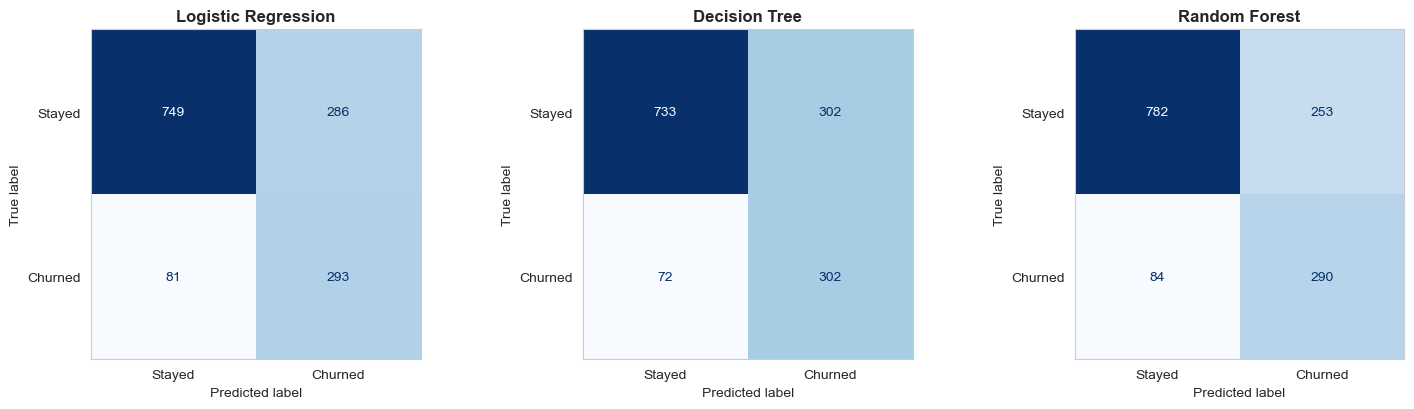

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], display_labels=['Stayed', 'Churned'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name, fontweight='bold')
    ax.grid(False)
plt.tight_layout()
plt.show()

###  ROC Curves
The closer a curve is to the top-left corner, the better the model separates churners from non-churners.

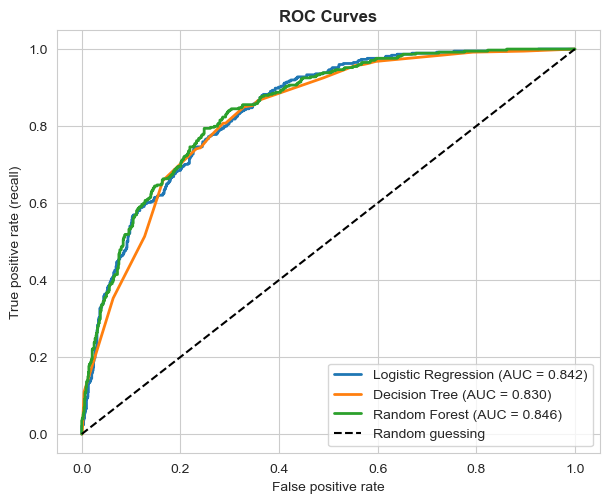

In [37]:
plt.figure(figsize=(7, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {roc_auc_score(y_test, probabilities[name]):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC Curves', fontweight='bold')
plt.legend(loc='lower right')
plt.show()

**Model results:**
- **Random Forest** has the best overall ROC-AUC (**0.846**) and accuracy (**76.1%**), followed very closely by **Logistic Regression** (0.842). The Decision Tree is slightly behind (0.830) but catches the most churners (recall 0.807).
- All three models identify roughly **78-81% of the customers who actually churn** (recall). That is the main goal here.
- **Precision is about 0.50-0.53**: roughly half of the customers flagged as "likely to churn" really would leave. This is the price of catching most churners.
- Accuracy (74-76%) looks only slightly above the 73.5% we would get by always predicting "No churn", but that naive model would catch **0%** of churners. This is why recall, F1 and ROC-AUC matter more than accuracy here.
- The simple Logistic Regression performs almost as well as the Random Forest.

In [38]:
best_model_name = results_df['ROC-AUC'].idxmax()
print('Detailed report for the best model by ROC-AUC:', best_model_name, '\n')
print(classification_report(y_test, predictions[best_model_name], target_names=['Stayed', 'Churned']))

Detailed report for the best model by ROC-AUC: Random Forest 

              precision    recall  f1-score   support

      Stayed       0.90      0.76      0.82      1035
     Churned       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



##  What Drives Churn? (Feature Importance)
Finding which features have the biggest influence on the predictions.

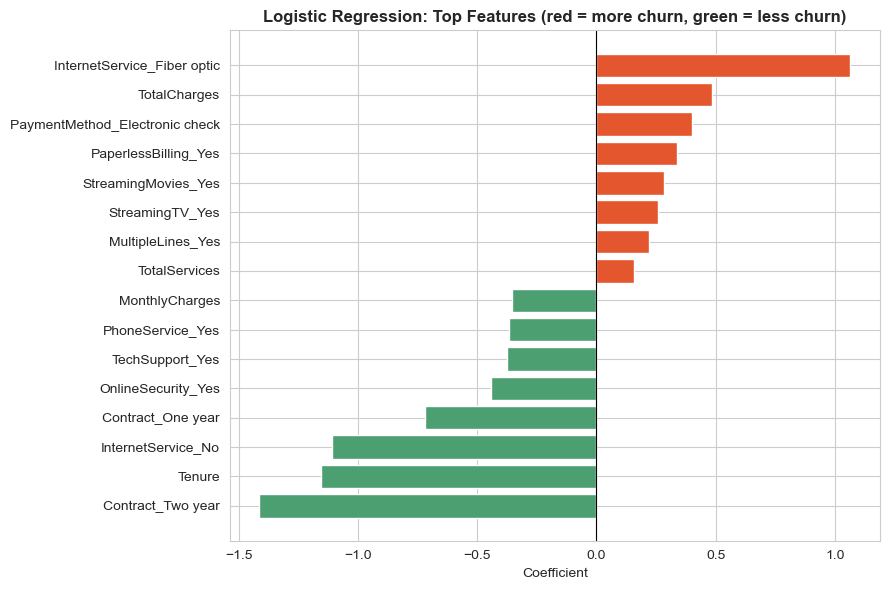

In [39]:
coefficients = pd.Series(models['Logistic Regression'][0].coef_[0], index=X.columns).sort_values()
top_coef = pd.concat([coefficients.head(8), coefficients.tail(8)])

plt.figure(figsize=(9, 6))
colors = ['#4C9F70' if v < 0 else '#E4572E' for v in top_coef.values]
plt.barh(top_coef.index, top_coef.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression: Top Features (red = more churn, green = less churn)', fontweight='bold')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

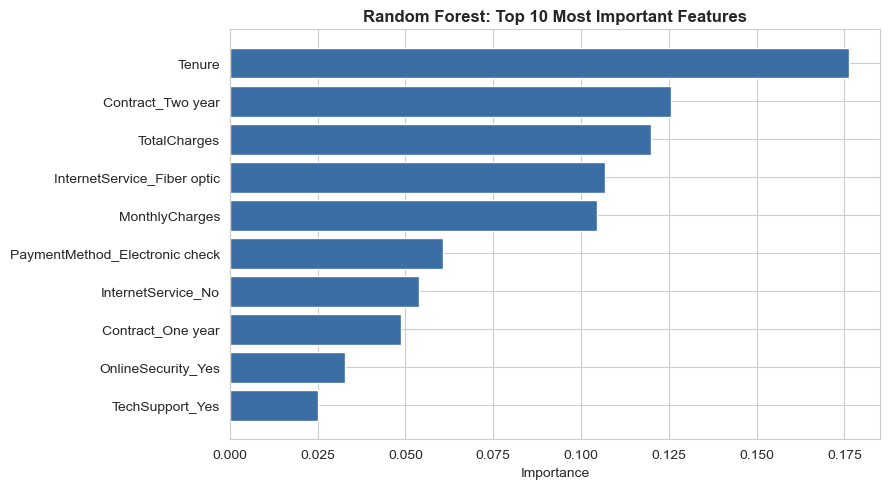

In [40]:
importances = pd.Series(models['Random Forest'][0].feature_importances_, index=X.columns)
top_imp = importances.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top_imp.index, top_imp.values, color='#3A6EA5')
plt.title('Random Forest: Top 10 Most Important Features', fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

**Insights:**
- **Reduce churn risk:** a **two-year contract**, a **one-year contract**, **long tenure**, having **no internet service**, and having **Online Security** or **Tech Support**.
- **Increase churn risk:** **fiber optic internet**, **electronic check** payment, **paperless billing** and streaming services.
- In the Random Forest, the most important features are **tenure, contract type, total charges, fiber optic internet and monthly charges**.
- `MonthlyCharges` and `TotalCharges` appear with unexpected signs in Logistic Regression because they overlap strongly with tenure and the service columns. For these columns, rely on the Random Forest importance and the EDA charts instead of the coefficient signs.

This confirms the EDA: **contract type, tenure and internet/support services** are the main drivers of churn.

##  Conclusions and Business Recommendations

### Key Conclusions
1. **26.5% of customers churn**, which puts about **30.5% of monthly revenue** at risk (roughly \$1.67 million per year).
2. Churn is concentrated among **new customers**, **month-to-month contracts**, **fiber optic users**, **electronic check payers** and customers **without security or tech support**. Gender does not matter.
3. A Random Forest model predicts churn with an **ROC-AUC of about 0.85** and catches about **78% of churners**. A simpler Logistic Regression performs almost as well.

### Business Recommendations
| # | Recommendation | Why (evidence from this project) |
|---|---|---|
| 1 | **Offer discounts or perks to move month-to-month customers to 1-2 year contracts** | Month-to-month churn is 42.7%, versus 11.3% (1 year) and 2.8% (2 years) |
| 2 | **Create a strong onboarding program for the first 12 months** (welcome call, check-ins, early support) | 47.4% churn in the first year; 55% of churners leave within 12 months |
| 3 | **Bundle Online Security and Tech Support** into plans, especially for fiber customers | Customers with these services churn about 15% vs about 42% without them |
| 4 | **Encourage automatic payments** with a small incentive | Electronic check users churn at 45.3% vs 15-17% for automatic payment |
| 5 | **Investigate fiber optic service quality and pricing** | Fiber churn is 41.9% versus 19.0% for DSL |
| 6 | **Use the model to flag high-risk customers** for proactive retention offers | The model identifies about 78% of future churners |

